In [2]:
%load_ext autoreload
%autoreload 2
import emcee
import corner
import pickle
import time
from astropy.table import QTable
from astropy import units as u
from astropy import constants as const
import pandas as pd

from multiprocessing import Pool

import numpy as np
from matplotlib import pyplot as plt


from nfw_profile_heating import NFWProfile
from statistics_functions import chi_squared
from plotting import savefig, paper_plot
from load_data_and_var import load_data_and_var, generate_nfws_from_combined_dataset_werr, generate_nfws_from_combined_dataset

Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.
Intel MKL WARNING: Support of Intel(R) Streaming SIMD Extensions 4.2 (Intel(R) SSE4.2) enabled only processors has been deprecated. Intel oneAPI Math Kernel Library 2025.0 will require Intel(R) Advanced Vector Extensions (Intel(R) AVX) instructions.


In [3]:
reflex_clean, variances = load_data_and_var()
reflex_clean.head()

,MCXC,OName,AName,Ah Am RAs Ed Em Es,RAdeg DEdeg,GLON GLAT,z_x,Cat,Sub-Cat,Scale,...,E_MSZ,e_MSZ,RedMAPPer,ACT,SPT,ISE,AMIevi,O,Comment,L_err
1,J0003.1-0605,RXCJ0003.1-0605,A2697,0 3 11.8 - 6 5 10,0.799 -6.086,92.169 -66.033,0.2320,NORAS/REFLEX,REFLEX,3.698,...,0.368165,0.369144,RMJ000311.6-060530.1,,,-10,-1000.0,1,NaN,0.617909
2,J0003.8+0203,RXCJ0003.8+0203,A2700,0 3 50.6 + 2 3 48,0.961 2.063,99.610 -58.637,0.0924,NORAS/REFLEX,REFLEX,1.719,...,0.282160,0.301448,RMJ000349.7+020359.3,,,-10,-1000.0,0,NaN,0.147037
3,J0006.0-3443,RXCJ0006.0-3443,A2721,0 6 3.0 -34 43 27,1.513 -34.724,352.147 -77.668,0.1147,NORAS/REFLEX,REFLEX,2.080,...,0.248869,0.226974,,,,-10,-1000.0,1,NaN,0.227619
6,J0011.3-2851,RXCJ0011.3-2851,A2734,0 11 20.7 -28 51 18,2.836 -28.855,19.562 -80.986,0.0620,NORAS/REFLEX,REFLEX,1.195,...,0.182667,0.188038,,,,-10,-1000.0,1,NaN,0.092959
9,J0013.6-1930,RXCJ0013.6-1930,A0013,0 13 38.3 -19 30 8,3.409 -19.502,72.276 -78.456,0.0940,NORAS/REFLEX,REFLEX,1.746,...,0.233331,0.245311,,,,-10,-1000.0,1,NaN,0.133542


Text(0, 0.5, '$\\mathrm{Number~of~Clusters}$')

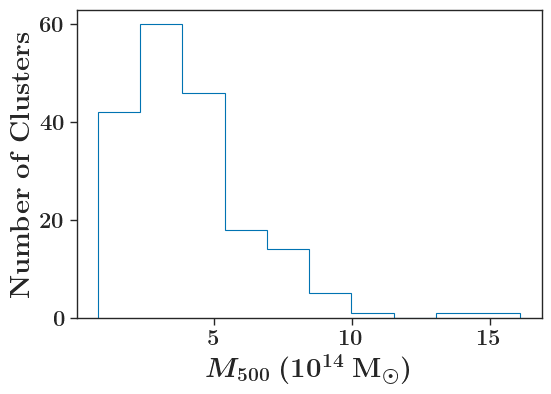

In [4]:
paper_plot()
fig = plt.figure()
plt.hist(reflex_clean['MSZ'], histtype='step')
plt.xlabel(f'$M_{{500}} ~ (10^{{14}} ~\mathrm{{M_{{\odot}}}})$')
plt.ylabel(f'$\mathrm{{Number~of~Clusters}}$')

Text(0, 0.5, '$\\mathrm{Number~of~Clusters}$')

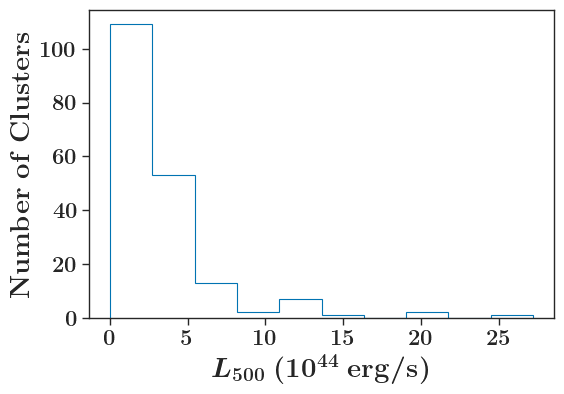

In [5]:


#plt.xlabel(f'$L500 (10^{{14}} Msun)$')
plt.hist(reflex_clean['L500'], histtype='step')
plt.xlabel(f'$L_{{500}}~ (10^{{44}} ~ \mathrm{{erg/s}})$')
plt.ylabel(f'$\mathrm{{Number~of~Clusters}}$')

Text(0, 0.5, '$\\mathrm{Number~of~Clusters}$')

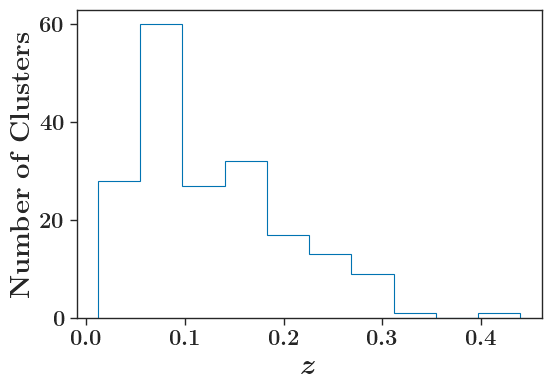

In [6]:
plt.hist(reflex_clean['z_y'], histtype='step')
plt.xlabel(f'$z$')
plt.ylabel(f'$\mathrm{{Number~of~Clusters}}$')

In [7]:
reflex_clean

,MCXC,OName,AName,Ah Am RAs Ed Em Es,RAdeg DEdeg,GLON GLAT,z_x,Cat,Sub-Cat,Scale,...,E_MSZ,e_MSZ,RedMAPPer,ACT,SPT,ISE,AMIevi,O,Comment,L_err
1,J0003.1-0605,RXCJ0003.1-0605,A2697,0 3 11.8 - 6 5 10,0.799 -6.086,92.169 -66.033,0.2320,NORAS/REFLEX,REFLEX,3.698,...,0.368165,0.369144,RMJ000311.6-060530.1,,,-10,-1000.0,1,NaN,0.617909
2,J0003.8+0203,RXCJ0003.8+0203,A2700,0 3 50.6 + 2 3 48,0.961 2.063,99.610 -58.637,0.0924,NORAS/REFLEX,REFLEX,1.719,...,0.282160,0.301448,RMJ000349.7+020359.3,,,-10,-1000.0,0,NaN,0.147037
3,J0006.0-3443,RXCJ0006.0-3443,A2721,0 6 3.0 -34 43 27,1.513 -34.724,352.147 -77.668,0.1147,NORAS/REFLEX,REFLEX,2.080,...,0.248869,0.226974,,,,-10,-1000.0,1,NaN,0.227619
6,J0011.3-2851,RXCJ0011.3-2851,A2734,0 11 20.7 -28 51 18,2.836 -28.855,19.562 -80.986,0.0620,NORAS/REFLEX,REFLEX,1.195,...,0.182667,0.188038,,,,-10,-1000.0,1,NaN,0.092959
9,J0013.6-1930,RXCJ0013.6-1930,A0013,0 13 38.3 -19 30 8,3.409 -19.502,72.276 -78.456,0.0940,NORAS/REFLEX,REFLEX,1.746,...,0.233331,0.245311,,,,-10,-1000.0,1,NaN,0.133542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
543,J2347.7-2808,RXCJ2347.7-2808,A4038,23 47 43.2 -28 8 29,356.930 -28.141,25.139 -75.862,0.0300,NORAS/REFLEX,REFLEX,0.601,...,0.114748,0.107849,,,,-10,-1000.0,1,NaN,0.038488
546,J2351.6-2605,RXCJ2351.6-2605,A2667,23 51 40.7 -26 5 1,357.919 -26.084,34.017 -76.609,0.2264,NORAS/REFLEX,REFLEX,3.631,...,0.365168,0.382711,,,,-10,-1000.0,1,NaN,0.993468
547,J2354.2-1024,RXCJ2354.2-1024,A2670,23 54 13.4 -10 24 46,358.556 -10.413,81.334 -68.530,0.0765,NORAS/REFLEX,REFLEX,1.450,...,0.216913,0.225417,RMJ235413.7-102508.5,,,-10,-1000.0,1,NaN,0.151354
549,J2357.0-3445,RXCJ2357.0-3445,A4059,23 57 2.3 -34 45 38,359.260 -34.761,356.359 -76.082,0.0475,NORAS/REFLEX,REFLEX,0.931,...,0.163126,0.149009,,,,-10,-1000.0,1,NaN,0.091267


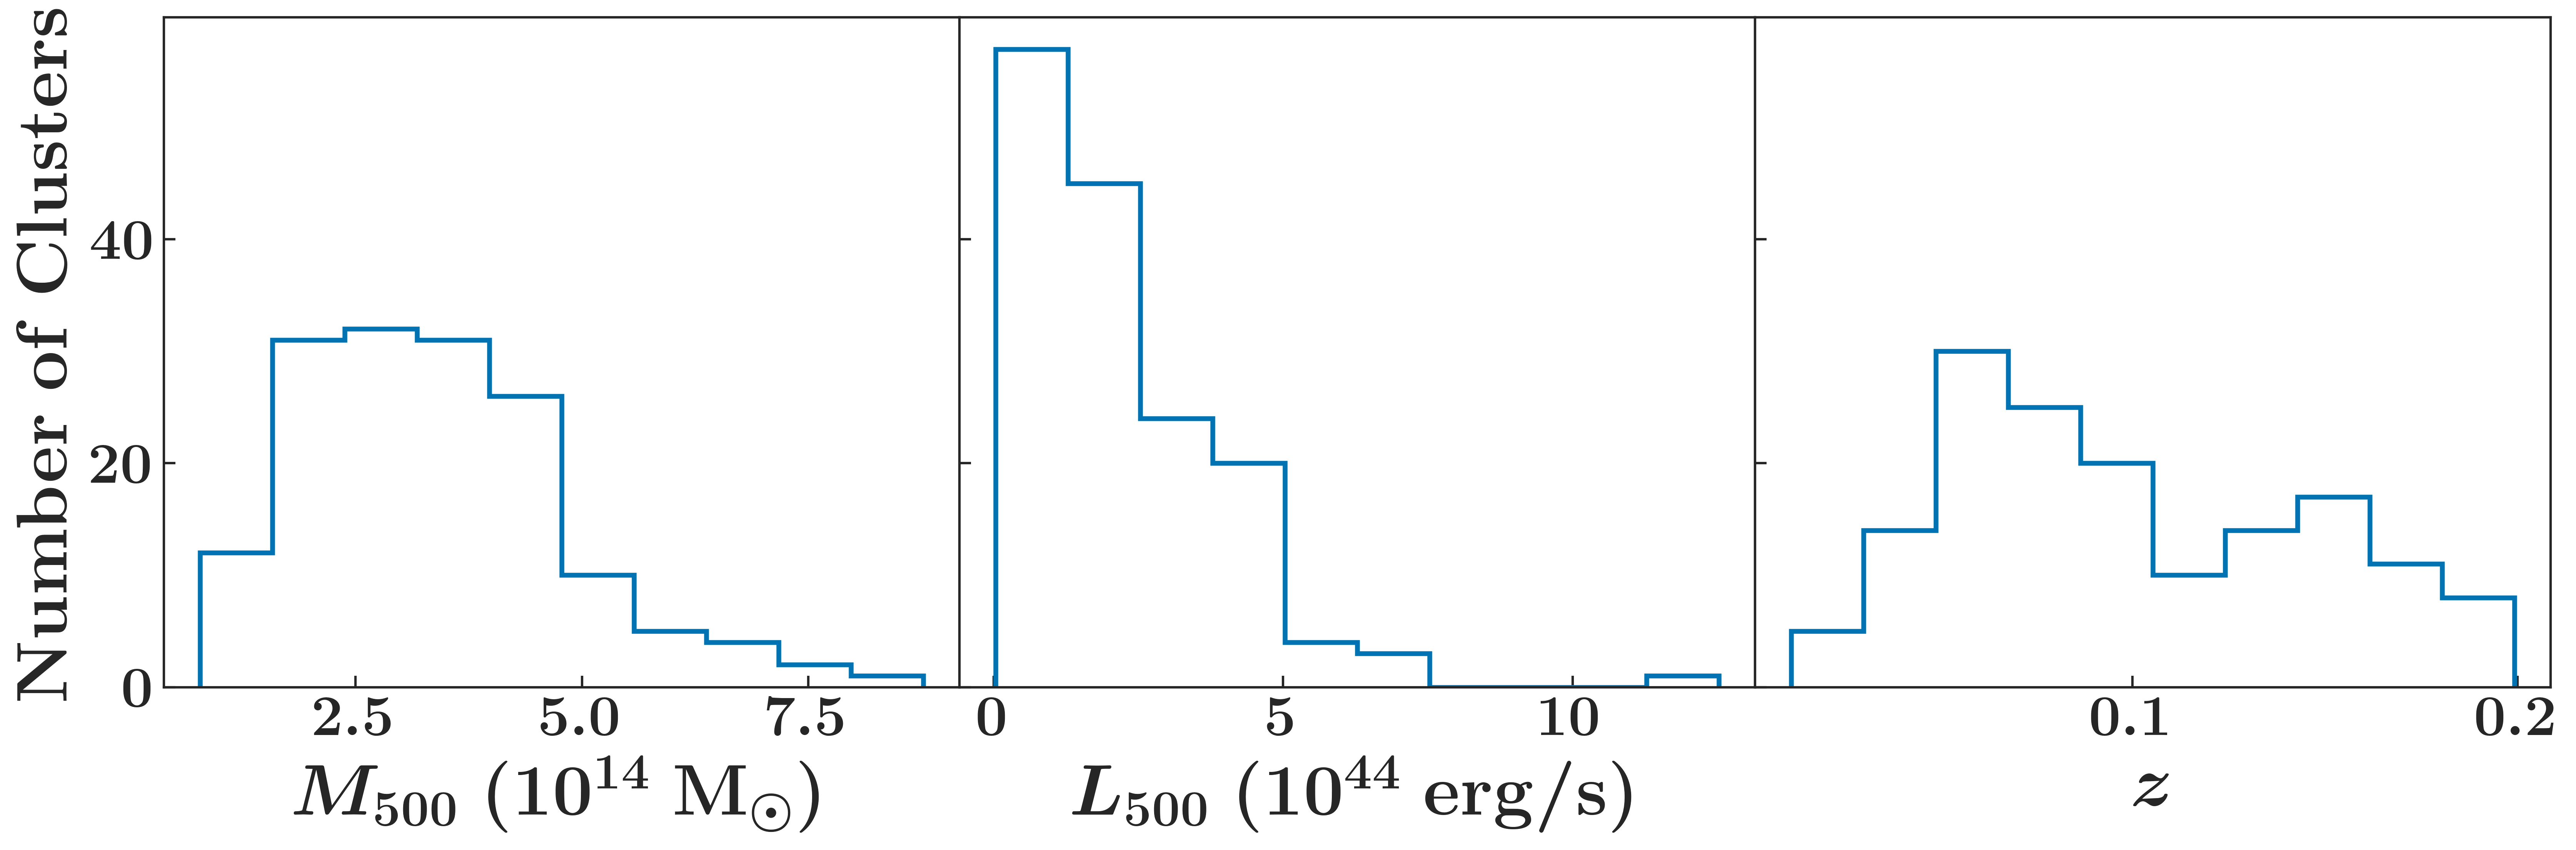

In [8]:
    lowz_data = reflex_clean[reflex_clean['z_y'] < 0.2]
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True, gridspec_kw={'wspace': 0}, dpi=450)  # 1 row, 3 columns

    # First subplot
    axes[0].hist(lowz_data['MSZ'], histtype='step', lw=2)
    axes[0].set_xlabel(f'$M_{{500}} ~ (10^{{14}} ~\\mathrm{{M_{{\\odot}}}})$', size=30)
    axes[0].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$', size=30)

    # Second subplot
    axes[1].hist(lowz_data['L500'], histtype='step', lw=2)
    axes[1].set_xlabel(f'$L_{{500}}~ (10^{{44}} ~ \\mathrm{{erg/s}})$', size=30)
    #axes[1].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$')

    # Third subplot
    axes[2].hist(lowz_data['z_y'], histtype='step', lw=2)
    axes[2].set_xlabel(f'$z$', size=30)
    #axes[2].set_ylabel(f'$\\mathrm{{Number~of~Clusters}}$')


    [ax.tick_params(axis='both', labelsize='24', direction='in') for ax in axes]
    plt.tight_layout()  # Adjusts the layout so the labels and titles fit within the figure
    plt.show()
    
    fig.savefig('plots/REFLEX_clusters.pdf', bbox_inches='tight')

In [9]:
nfws_werr = generate_nfws_from_combined_dataset_werr(reflex_clean, variances)
# grab only low z clusters
nfws_subset = [nfw for nfw in nfws_werr if nfw.z < 0.2]
#L_obs = np.array([nfw.L500.to(u.erg/u.s).value for nfw in nfws_subset])
#variances_obs = np.array([nfw.L_err for nfw in nfws_subset])

In [10]:
(1e37*u.W).to(u.erg/u.s)

<Quantity 1.e+44 erg / s>

In [11]:
heating_rates = [nfw.total_heating_rate(0.001*nfw.R500, nfw.R500, 0.1*nfw.R500).value for nfw in nfws_subset]

In [192]:
heating_rates[0].value

4.169943111585336e+44

In [193]:
cooling_rates = [nfw.total_cooling_rate(0.001*nfw.R500, nfw.R500) for nfw in nfws_subset]

In [194]:
cooling_rates[0].value

8.188335573067685e+44

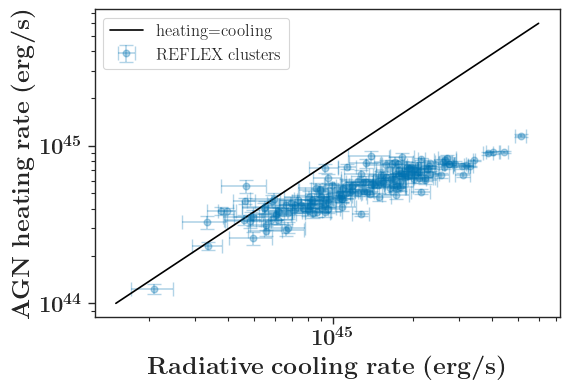

In [411]:
#plt.scatter(cooling_rates, heating_rates)
plt.errorbar(cooling_rates, [h for h in heating_rates],
             xerr=[[c.minus for c in cooling_rates],[c.plus for c in cooling_rates]],
             yerr=[[h.minus for h in heating_rates],[h.plus for h in heating_rates]], 
             fmt='o', capsize=5, capthick=1, alpha=0.3, label='REFLEX clusters')


plt.plot([1.5e44, 6e45], [1e44, 6e45], label='heating=cooling', c='k')
plt.xscale('log')
plt.yscale('log')

#plt.xlim(2e44, 6e45)
#plt.ylim(2e44, 6e45)
plt.ylabel(f'$\mathrm{{AGN~heating~rate~(erg/s)}}$', size=18)
plt.xlabel(f'$\mathrm{{Radiative~cooling~rate~(erg/s)}}$', size=18)
plt.legend()

In [147]:
max(cooling_rates).value, min(cooling_rates).value

(5.359582240930958e+45, 2.401139372880963e+44)

In [150]:
data = pd.DataFrame({'cool': np.array([c.value for c in cooling_rates]),
                     'heat': np.array([h.value for h in heating_rates]), 
                     'c_err': np.array([max(c.minus, c.plus) for c in cooling_rates]),
                     'h_err': np.array([max(h.minus, h.plus) for h in heating_rates])})

In [188]:
number_of_bins = 10

bin_edges = np.linspace(data['cool'].min(), data['cool'].max(), number_of_bins + 1)

In [169]:
def sem(x):
    if len(x) == 0:
        return 0
    return 1./len(x) * np.sqrt(np.sum(x**2)) 

In [164]:
sem(data['c_err'])

4.947224239037621e+44

In [189]:
# Assign each data point to a bin in linear space
data['bin'] = pd.cut(data['cool'], bins=bin_edges, include_lowest=True)

# Aggregate data within bins
binned_data = data.groupby('bin').agg({
    'cool': 'mean',
    'heat': 'mean',
    'c_err': sem,
    'h_err': sem  # or use np.std / np.sqrt(len) for SEM
}).reset_index(drop=True)

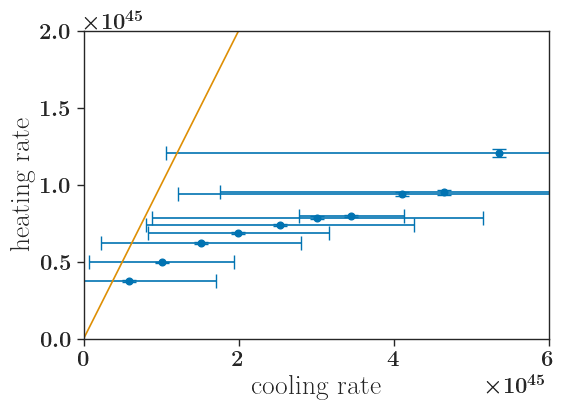

In [190]:
plt.errorbar(binned_data['cool'], binned_data['heat'], xerr=binned_data['c_err'], yerr=binned_data['h_err'], fmt='o', capsize=5)
plt.plot([0, 1e44, 1e46], [0, 1e44, 1e46], label='heating=cooling')
plt.xlabel('cooling rate')
plt.ylabel('heating rate')
#plt.title('Binned Data with Error Bars')
plt.xlim(0, 6e45)
plt.ylim(0, 2e45)
plt.show()


In [290]:
logmp = np.log10(const.m_p.to(u.GeV).value)
mchis = np.logspace(-4,logmp )*u.GeV

In [359]:
nfws_werr2 = generate_nfws_from_combined_dataset_werr(reflex_clean, variances, rmin=0.001)
# grab only low z clusters
nfws_subset2 = [nfw for nfw in nfws_werr2 if nfw.z < 0.2]

In [360]:
test_nfw = nfws_subset[2]
filtered_nfws2 = list(n for n in nfws_subset2 if n.total_heating_rate(0.001*n.R500, n.R500, 0.1*n.R500).value.value > n.total_cooling_rate(0.001*n.R500, n.R500).value)
filtered_nfws2

In [363]:
nfw = filtered_nfws2[0]
nfw.total_heating_rate(0.001*nfw.R500, nfw.R500, 0.1*nfw.R500).value.value, nfw.total_cooling_rate(0.001*nfw.R500, nfw.R500).value

(3.865398745879875e+44, 3.746263196147441e+44)

In [305]:
uth = np.sqrt(nfw.Tbs / const.m_p.to(u.GeV).value + nfw.Tx_by_mx)
uth[0].value, uth[-1].value

(0.000141659124659408, 0.0018742790875532303)

In [318]:
np.power(nfw.rvals, 2)

array([<asymmetric_uncertainty_mod.core.a_u object at 0x14973dc90>,
      dtype=object)

In [365]:


sigma0s = [nfw.sigma0_from_mchi(m, rmin=0.001, rmax=1).value for m in mchis]
sigma0s

[5.7493914025601236e-30,
 5.7497180067228925e-30,
 5.7501116566967935e-30,
 5.750586120363595e-30,
 5.751157994932536e-30,
 5.751847289317693e-30,
 5.7526781268170235e-30,
 5.7536795931369136e-30,
 5.754886760106727e-30,
 5.756341921889319e-30,
 5.7580960883874e-30,
 5.760210790214281e-30,
 5.7627602614758935e-30,
 5.7658340812551985e-30,
 5.769540372818392e-30,
 5.7740096821086335e-30,
 5.7793996852856664e-30,
 5.7859009105368335e-30,
 5.793743704309618e-30,
 5.803206729452019e-30,
 5.814627356535727e-30,
 5.828414405460154e-30,
 5.84506382008622e-30,
 5.8651780251145e-30,
 5.889489937356154e-30,
 5.918892905472565e-30,
 5.954478265939407e-30,
 5.9975827765765265e-30,
 6.049848994064505e-30,
 6.113302806150591e-30,
 6.190453976895495e-30,
 6.284427968083216e-30,
 6.399140860170311e-30,
 6.539534548063246e-30,
 6.711897566082176e-30,
 6.924309624371094e-30,
 7.18726814713331e-30,
 7.514587917217447e-30,
 7.924719587126553e-30,
 8.442726524848857e-30,
 9.103325552140752e-30,
 9.95570302

In [340]:
sigma0s_0001 = [nfw.sigma0_from_mchi(m, rmin=0.0001, rmax=1).value for m in mchis]

In [390]:
nfw2_test = filtered_nfws[1]
sigma0s2_test = [nfw2.sigma0_from_mchi(m, rmin=0.001, rmax=1) for m in mchis]

In [383]:
nfw2_test = filtered_nfws[1]
sigma0s2_test = [nfw2_test.sigma0_from_mchi(m, rmin=0.001, rmax=1).value for m in mchis]

In [385]:
sigma0s2_10xagn=[nfw2_test.sigma0_from_mchi(m, rmin=0.001, rmax=1, agn_factor=10).value for m in mchis]

In [391]:
sigma0s2_test

In [356]:
print(nfw2.rvals[0]*u.cm.to(u.Mpc))

7.872648117738105e-05 (+3.935885001997666e-06, -4.022728659089114e-06)


In [358]:
nfw2.rvals[0]*u.cm.to(u.Mpc)/nfw2.R500

In [341]:
sigma0s2_0001 = [nfw2.sigma0_from_mchi(m, rmin=0.0001, rmax=1).value for m in mchis]

In [325]:
sigma0s

[5.752830370060671e-30,
 5.753158082305246e-30,
 5.753553067947477e-30,
 5.754029141657414e-30,
 5.754602957071782e-30,
 5.755294591166387e-30,
 5.7561282493471984e-30,
 5.7571331163930514e-30,
 5.758344383703348e-30,
 5.759804489790223e-30,
 5.761564618879326e-30,
 5.7636865121906195e-30,
 5.7662446583975626e-30,
 5.769328944469385e-30,
 5.77304786630868e-30,
 5.777532421245803e-30,
 5.78294083277807e-30,
 5.78946429358568e-30,
 5.797333958016031e-30,
 5.806829472880745e-30,
 5.818289409628653e-30,
 5.8321240573729696e-30,
 5.848831162724277e-30,
 5.869015370003733e-30,
 5.8934123399896304e-30,
 5.922918829644658e-30,
 5.958630432395588e-30,
 6.0018892571982495e-30,
 6.054344637273595e-30,
 6.118031115137119e-30,
 6.195469615766598e-30,
 6.289800151906663e-30,
 6.404958009149503e-30,
 6.545910780354914e-30,
 6.718981913303549e-30,
 6.932299357359407e-30,
 7.196428437539073e-30,
 7.525281491126989e-30,
 7.937452539425588e-30,
 8.45822101868637e-30,
 9.122638692419633e-30,
 9.9804279766

In [401]:
s0_95_contour = np.add([s.value for s in sigma0s2_test], [2*max(s.plus, s.minus) for s in sigma0s2_test])

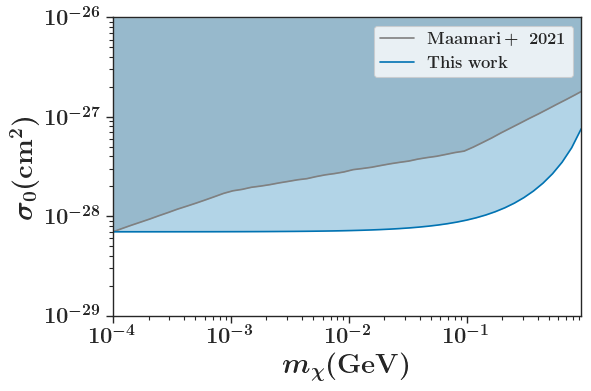

In [405]:
import pandas as pd
maamari = pd.read_csv('data/maamari_2021_constraint.csv', header=None)
plt.loglog(maamari[0], maamari[1], label=f"$\mathrm{{Maamari+~2021}}$", color='gray')
#plt.loglog(mchis, sigma0s, label="nfw",)
#plt.loglog(mchis, sigma0s_0001, label="nfw 0001",)
#plt.loglog(mchis, sigma0s2_test, label=f"$\mathrm{{This~work}}$",)
#plt.loglog(mchis, sigma0s2_10xagn, label=f"$\mathrm{{This~work}}$",)
#plt.loglog(mchis, sigma0s2_0001, label="nfw2 0001",)
plt.plot(mchis,
           s0_95_contour,label=f"$\mathrm{{This~work}}$")
             #yerr=[[d.plus for d in sigma0s2_test],
             #      [d.minus for d in sigma0s2_test]],)


plt.legend()
plt.xlabel(r"$m_{\chi} \mathrm{(GeV)}$")
plt.ylabel(r"$\sigma_0 (\mathrm{cm}^2)$")
#plt.xlabel("DM particle mass (GeV)")
#plt.ylabel(r"Interaction cross section (cm$^2$)")

plt.fill_between(
                    maamari[0], maamari[1],
                    y2=1e-26,
                    alpha=0.3, color='gray'
                )

plt.fill_between(
                    mchis.value,
                    s0_95_contour,
                    y2=1e-26,
                    alpha=0.3,
                )
#plt.title('n=0')
plt.xlim(1e-4, const.m_p.to(u.GeV).value)
plt.ylim(1e-29, 1e-26)
plt.tight_layout()
plt.savefig('constraint.png', dpi=450)

In [389]:
np.divide(sigma0s2_10xagn,sigma0s2_test)

array([56.44562346, 56.44562346, 56.44562346, 56.44562346, 56.44562346,
       56.44562346, 56.44562346, 56.44562346, 56.44562346, 56.44562346,
       56.44562346, 56.44562346, 56.44562346, 56.44562346, 56.44562346,
       56.44562346, 56.44562346, 56.44562346, 56.44562346, 56.44562346,
       56.44562346, 56.44562346, 56.44562346, 56.44562346, 56.44562346,
       56.44562346, 56.44562346, 56.44562346, 56.44562346, 56.44562346,
       56.44562346, 56.44562346, 56.44562346, 56.44562346, 56.44562346,
       56.44562346, 56.44562346, 56.44562346, 56.44562346, 56.44562346,
       56.44562346, 56.44562346, 56.44562346, 56.44562346, 56.44562346,
       56.44562346, 56.44562346, 56.44562346, 56.44562346, 56.44562346])

NameError: name 'nfws_subset' is not defined